<a href="https://colab.research.google.com/github/allnlk/ML/blob/main/%D0%9A%D1%83%D0%B1%D1%80%D0%B0%D0%BA_3_10_%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_ML_%D0%B4%D0%B6%D1%83%D0%BD%D1%96%D0%BE%D1%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

In [2]:
import kagglehub

path = kagglehub.dataset_download('gauravtopre/bank-customer-churn-dataset')
csv_file = glob.glob(os.path.join(path, '*.csv'))[0]
df = pd.read_csv(csv_file)
df.head()

100%|██████████| 187k/187k [00:00<00:00, 33.7MB/s]

Extracting files...


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


customer_id — Унікальний ідентифікатор клієнта.

credit_score — Кредитний рейтинг клієнта.

country — Країна проживання клієнта.

gender — Стать клієнта.

age — Вік клієнта у роках.

tenure — Кількість років, протягом яких клієнт користується послугами банку.

balance — Баланс на рахунку клієнта.

products_number — Кількість банківських продуктів, якими користується клієнт.

credit_card — Наявність у клієнта кредитної картки.

active_member — Статус активного клієнта банку.

estimated_salary — Орієнтовна річна заробітна плата клієнта.

churn — Цільова змінна: чи припинив клієнт співпрацю з банком.

In [3]:
print('Розмір:', df.shape)
df.info()

Розмір: (10000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [4]:
df.isnull().sum()

,0
customer_id,0
credit_score,0
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0


In [5]:
print('Дублікатів:', df.duplicated().sum())
df.describe()

Дублікатів: 0


,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


churn
0    7963
1    2037
Name: count, dtype: int64
churn
0    0.7963
1    0.2037
Name: proportion, dtype: float64


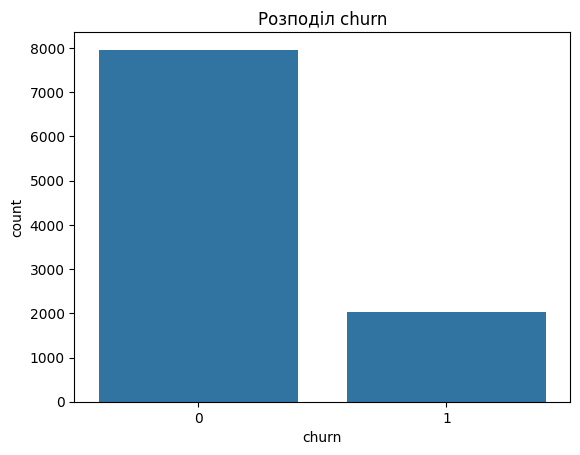

In [6]:
print(df['churn'].value_counts())
print(df['churn'].value_counts(normalize=True))

sns.countplot(x='churn', data=df)
plt.title('Розподіл churn')
plt.show()

In [7]:
print(df.groupby('country')['churn'].mean())
print()
print(df.groupby('gender')['churn'].mean())

country
France     0.161548
Germany    0.324432
Spain      0.166734
Name: churn, dtype: float64

gender
Female    0.250715
Male      0.164559
Name: churn, dtype: float64


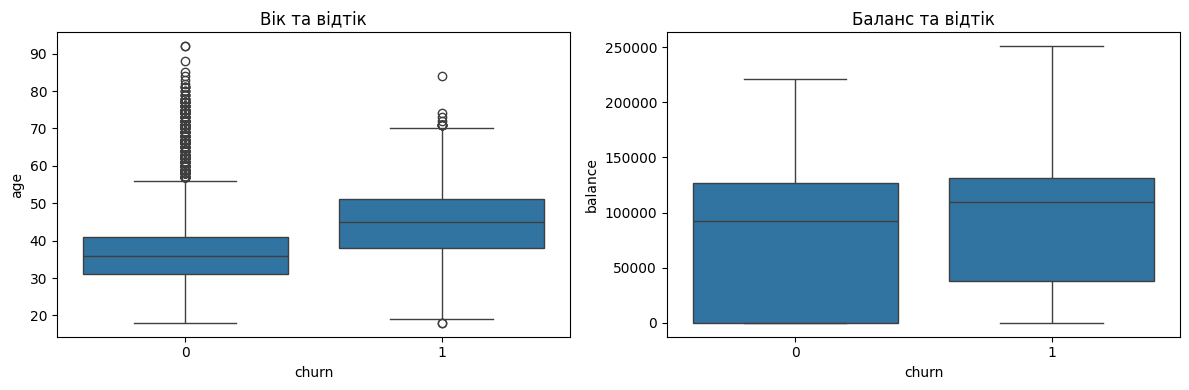

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x='churn', y='age', data=df)
plt.title('Вік та відтік')

plt.subplot(1, 2, 2)
sns.boxplot(x='churn', y='balance', data=df)
plt.title('Баланс та відтік')

plt.tight_layout()
plt.show()

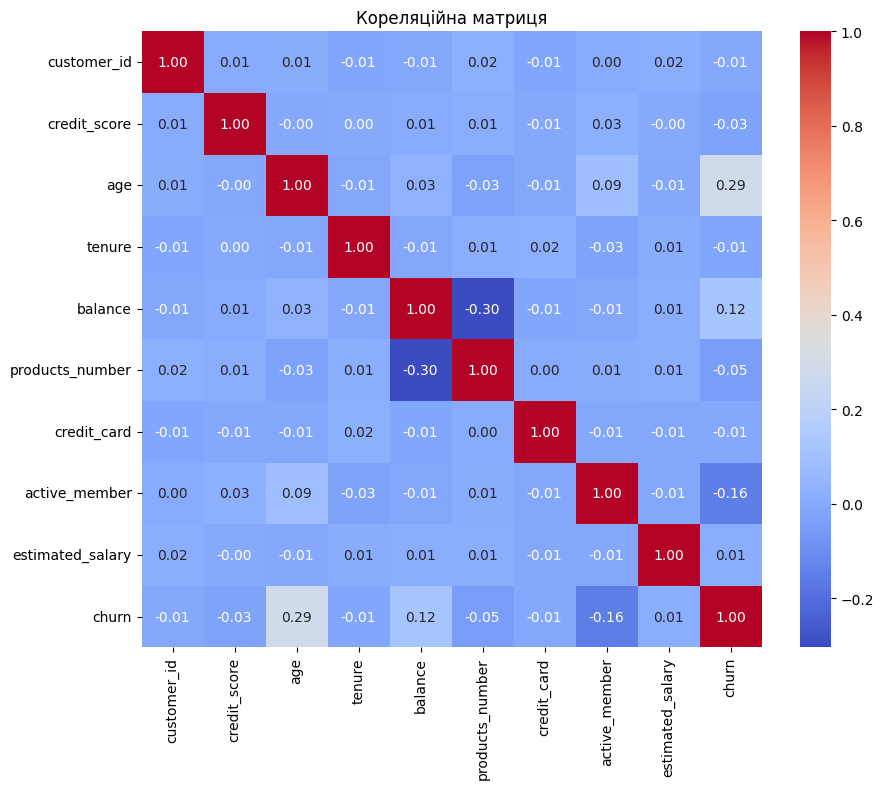

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.drop(columns=['country', 'gender']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Кореляційна матриця')
plt.show()

In [10]:
data = df.drop(columns=['customer_id']).copy()
data['gender'] = data['gender'].map({'Female': 0, 'Male': 1})
data = pd.get_dummies(data, columns=['country'], drop_first=True, dtype=int)
data.head()

,credit_score,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,1


In [11]:
X = data.drop(columns=['churn'])
y = data['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

(8000, 11) (2000, 11)
0.20375 0.2035


In [12]:
models = {
    'Логістична регресія': (LogisticRegression(max_iter=1000, random_state=42), True),
    'SVM': (SVC(random_state=42), True),
    'Дерево рішень': (DecisionTreeClassifier(random_state=42), False),
    'Random Forest': (RandomForestClassifier(random_state=42), False)
}

results = []
for name, (clf, scaled) in models.items():
    Xtr = X_train_scaled if scaled else X_train
    Xte = X_test_scaled if scaled else X_test
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xte)
    results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'F1-score': f1_score(y_test, pred)
    })

result_df = pd.DataFrame(results).sort_values('F1-score', ascending=False)
print(result_df.round(3).to_string(index=False))

             Модель  Accuracy  F1-score
      Random Forest     0.861     0.570
                SVM     0.861     0.537
      Дерево рішень     0.786     0.499
Логістична регресія     0.808     0.284


In [13]:
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 3, 5],
    'class_weight': [None, 'balanced']
}

grid_search_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_search_rf.fit(X_train, y_train)

print('Найкращі параметри:', grid_search_rf.best_params_)
print('Найкращий CV F1-score:', grid_search_rf.best_score_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Найкращі параметри: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 100}
Найкращий CV F1-score: 0.62497167155155


In [14]:
best_model = grid_search_rf.best_estimator_
y_pred = best_model.predict(X_test)

print('Accuracy (після підбору):', accuracy_score(y_test, y_pred))
print('F1-score (після підбору):', f1_score(y_test, y_pred))

rf_before = result_df[result_df['Модель'] == 'Random Forest'].iloc[0]
print('Accuracy (до підбору):', rf_before['Accuracy'])
print('F1-score (до підбору):', rf_before['F1-score'])

Accuracy (після підбору): 0.8375
F1-score (після підбору): 0.6285714285714286
Accuracy (до підбору): 0.861
F1-score (до підбору): 0.5696594427244582


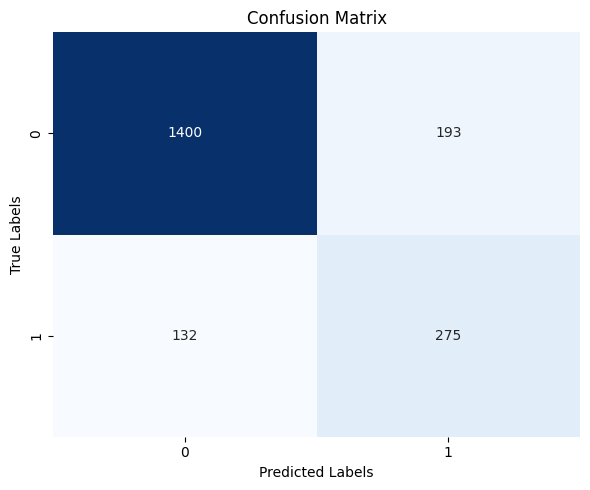

              precision    recall  f1-score   support

           0       0.91      0.88      0.90      1593
           1       0.59      0.68      0.63       407

    accuracy                           0.84      2000
   macro avg       0.75      0.78      0.76      2000
weighted avg       0.85      0.84      0.84      2000



In [15]:
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred))

In [16]:
def ask_client():
    client = {}
    client['credit_score'] = int(input('Credit score (350-850): '))
    gender = input('Стать (F/M): ').strip().upper()
    client['gender'] = 0 if gender == 'F' else 1
    client['age'] = int(input('Вік: '))
    client['tenure'] = int(input('Років у банку (0-10): '))
    client['balance'] = float(input('Баланс: '))
    client['products_number'] = int(input('Кількість продуктів (1-4): '))
    client['credit_card'] = int(input('Є кредитна картка (1 - так, 0 - ні): '))
    client['active_member'] = int(input('Активний клієнт (1 - так, 0 - ні): '))
    client['estimated_salary'] = float(input('Орієнтовна зарплата: '))
    country = input('Країна (France/Germany/Spain): ').strip().capitalize()
    client['country_Germany'] = 1 if country == 'Germany' else 0
    client['country_Spain'] = 1 if country == 'Spain' else 0
    return client


def predict_churn(client):
    row = pd.DataFrame([client], columns=X.columns)
    pred = best_model.predict(row)[0]
    proba = best_model.predict_proba(row)[0][1]
    return pred, proba


client = ask_client()
pred, proba = predict_churn(client)
print('Клієнт ПІДЕ' if pred == 1 else 'Клієнт ЗАЛИШИТЬСЯ', '| ймовірність відтоку:', round(proba, 3))

Credit score (350-850): 500
Стать (F/M): F
Вік: 19
Років у банку (0-10): 1
Баланс: 200
Кількість продуктів (1-4): 1
Є кредитна картка (1 - так, 0 - ні): 1
Активний клієнт (1 - так, 0 - ні): 1
Орієнтовна зарплата: 13000
Країна (France/Germany/Spain): Spain
Клієнт ЗАЛИШИТЬСЯ | ймовірність відтоку: 0.29


In [17]:
example_client = {
    'credit_score': 600, 'gender': 0, 'age': 45, 'tenure': 3,
    'balance': 100000, 'products_number': 1, 'credit_card': 1,
    'active_member': 0, 'estimated_salary': 80000,
    'country_Germany': 1, 'country_Spain': 0
}
pred, proba = predict_churn(example_client)
print('Клієнт ПІДЕ' if pred == 1 else 'Клієнт ЗАЛИШИТЬСЯ', '| ймовірність відтоку:', round(proba, 3))

Клієнт ПІДЕ | ймовірність відтоку: 0.862


**Висновок:** ключовими факторами відтоку клієнтів є вік, баланс на рахунку, країна проживання та статус активного учасника. Початкове порівняння чотирьох класифікаторів визначило RandomForestClassifier та SVM найкращими за якістю, тоді як проста логістична регресія показала найнижчий F1-score через дисбаланс класів.Оптимізація гіперпараметрів випадкового лісу з урахуванням ваги класів покращила здатність моделі виявляти відтік, підвищивши F1-score до 0.629.Побудована матриця помилок та класифікаційний звіт підтверджують збалансовану роботу фінальної моделі з прийнятною точністю на мінорному класі відтоку.Створена функція прогнозування успішно приймає характеристики нового клієнта і видає чіткий результат щодо ймовірності його відтоку чи збереження.